# Projeto Prático de Classificação — CIN0209 Aprendizado de Máquina 1
## Entrega 2 — comparação das famílias de modelos com validação cruzada

**Dupla:** Eduardo Neves e Wallace Santana  
**Conjunto de dados:** Online Shoppers Purchasing Intention (UCI, id 468) — alvo binário `Revenue`  
**Continuação da Entrega 1** (mesmo conjunto de dados, mesma divisão e mesma semente)

## Seção 0 — Instruções

- **Dados:** baixados automaticamente do UCI via pacote `ucimlrepo` (id 468). Não há arquivo de dados para enviar.
- **Divisão da Entrega 1:** reproduzida na Seção 2 a partir da mesma semente (`SEED = 42`) e das mesmas proporções (60/20/20, estratificada). Não há arquivo de divisão salvo: ela é regenerada de forma determinística e conferida contra os tamanhos e as proporções da E1.
- **Kit da disciplina (`am1_util.py`):** não utilizado. O protocolo foi implementado diretamente com scikit-learn, o que o guia da entrega permite.
- **Arquivos gerados pelo próprio notebook:** `test_log.csv` (registro de uso do teste) e `test_resultados.json` (resultado do teste, gravado na primeira e única avaliação). Se quiserem que sobrevivam a uma queda da sessão, montem o Google Drive e troquem `LOG_PATH`/`RES_PATH` na Seção 7 para uma pasta do Drive.
- **Como executar:** *Ambiente de execução → Reiniciar e executar tudo*. A Seção 7 só avalia o teste depois que `TESTE_LIBERADO` for mudada para `True` (ver Seção 7).
- **Tempo aproximado da execução completa:** cerca de 6 a 9 minutos (6,3 min na execução de referência; o valor exato é impresso na última célula).

In [ ]:
!pip install -q ucimlrepo

import time, json, os, warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

T0 = time.time()          # para medir o tempo total da execução
SEED = 42                 # mesma semente da Entrega 1

warnings.filterwarnings('ignore')   # silencia avisos de convergência do Perceptron/MLP durante a busca
sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

## Seção 1 — Problema e dados

**Pergunta que o projeto responde:** dado o comportamento de navegação de um visitante em uma sessão de um site de e-commerce (páginas visitadas, tempo em cada tipo de página, métricas de engajamento e contexto de acesso), é possível prever se a sessão termina em compra (`Revenue = 1`) ou não (`Revenue = 0`)? Trata-se de classificar sessões já concluídas, não de prever em tempo real durante a navegação.

**Fonte e licença:** [Online Shoppers Purchasing Intention Dataset](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset), UCI Machine Learning Repository (id 468), de Sakar, Polat, Katircioglu e Kastro (2018). Dados públicos, disponibilizados para uso acadêmico e de pesquisa.

**Tamanho:** 12.330 sessões, cada uma de um usuário distinto ao longo de um ano. Não há valores faltantes. A classe positiva (compra) é minoritária: cerca de 15,5% das sessões.

**Atributos:**

| Grupo | Atributos | Significado |
|---|---|---|
| Contagem e tempo por tipo de página | `Administrative`, `Informational`, `ProductRelated` e as respectivas `_Duration` | Nº de páginas de cada tipo visitadas na sessão e tempo total (s) gasto nelas |
| Métricas do site | `BounceRates`, `ExitRates`, `PageValues` | Taxa de rejeição, taxa de saída e valor médio da página (proxy de intenção de compra) |
| Calendário | `SpecialDay`, `Month`, `Weekend` | Proximidade de data comemorativa (0 a 1), mês e se foi fim de semana |
| Contexto de acesso | `OperatingSystems`, `Browser`, `Region`, `TrafficType`, `VisitorType` | Sistema, navegador, região e origem do tráfego (códigos sem ordem) e tipo de visitante |
| **Alvo** | **`Revenue`** | **A sessão terminou em compra?** |

**Principais achados da Entrega 1 (síntese):** `PageValues` é de longe o atributo mais discriminativo; `ExitRates` e `BounceRates` são menores nas sessões com compra; `Month` tem forte sazonalidade (novembro converte mais, fevereiro quase nada); há redundância entre `BounceRates`/`ExitRates` (correlação 0,91) e entre `ProductRelated`/`ProductRelated_Duration` (0,86).

### Devolutiva da Entrega 1 e correções incorporadas

Até a data desta entrega **não recebemos devolutiva da Entrega 1** (nota e comentários). Por isso, registramos aqui as correções que nós mesmos identificamos ao comparar a E1 com o protocolo da E2:

1. **Pré-processamento dentro do Pipeline.** Na E1, o `get_dummies` foi aplicado à base inteira antes da divisão e o `StandardScaler` foi ajustado no treino, mas fora de qualquer validação cruzada. Agora codificação e padronização vivem dentro de um `Pipeline` e são aprendidas em cada fold.
2. **Métrica principal.** Na E1 a escolha de hiperparâmetros usou acurácia, que engana com 85% de uma classe. Agora a métrica principal é a **acurácia balanceada**, com o F1 da classe positiva como métrica complementar.
3. **Validação cruzada no lugar de uma única validação.** A E1 escolhia hiperparâmetros em um único conjunto de validação; agora usamos validação cruzada estratificada com k = 5 no desenvolvimento (treino + validação da E1).
4. **Uso do teste na E1.** Na E1, o conjunto de teste foi consultado na Seção 5 (decomposição viés-variância e acurácia dos campeões). Os hiperparâmetros foram escolhidos pela validação, mas o teste não é mais totalmente virgem. Isso é tratado como limitação na Seção 9.

## Seção 2 — Mesma divisão e semente

Recuperamos a divisão da Entrega 1: primeiro 20% para teste, estratificado por `Revenue`, com `random_state = 42`; depois, do restante, 25% para validação (= 20% do total), também estratificado e com a mesma semente. O `train_test_split` estratificado só depende do alvo, do número de linhas e da semente, então o resultado é idêntico ao da E1 mesmo partindo dos dados brutos (sem o one-hot). As duplicatas (125 linhas) continuam mantidas, como na E1.

O **desenvolvimento** da E2 é treino + validação da E1. O teste continua separado e só é usado na Seção 7.

In [ ]:
from sklearn.model_selection import train_test_split

dataset = fetch_ucirepo(id=468)
df = pd.concat([dataset.data.features, dataset.data.targets], axis=1)

alvo = 'Revenue'
df[alvo] = df[alvo].astype(int)
df['Weekend'] = df['Weekend'].astype(int)

# Códigos sem ordem natural são categóricos (como na E1); Month e VisitorType já são texto
cat_cols = ['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
for c in ['OperatingSystems', 'Browser', 'Region', 'TrafficType']:
    df[c] = df[c].astype(str)
num_cols = [c for c in df.columns if c not in cat_cols + [alvo]]   # 10 numéricos + Weekend (0/1)

X = df.drop(columns=[alvo])
y = df[alvo]

# Mesma divisão da Entrega 1
X_temp, X_teste, y_temp, y_teste = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_treino, X_val, y_treino, y_val = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=SEED)

# Desenvolvimento = treino + validação da E1
X_dev = pd.concat([X_treino, X_val])
y_dev = pd.concat([y_treino, y_val])

print(f"Dados: {df.shape[0]} linhas, {len(num_cols)} atributos numéricos e {len(cat_cols)} categóricos")
print(f"Numéricos: {num_cols}")
print(f"Categóricos: {cat_cols}")

Dados: 12330 linhas, 11 atributos numéricos e 6 categóricos
Numéricos: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Weekend']
Categóricos: ['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']


In [ ]:
# Conferência contra a Entrega 1 (tamanhos e proporção de compras em cada parte)
esperado_e1 = {'Treino': (7398, 0.15477), 'Validação': (2466, 0.15450), 'Teste': (2466, 0.15491)}
reais = {'Treino': y_treino, 'Validação': y_val, 'Teste': y_teste}

linhas, tudo_ok = [], True
for nome, serie in reais.items():
    n_e1, p_e1 = esperado_e1[nome]
    ok = (len(serie) == n_e1) and (abs(serie.mean() - p_e1) < 1e-4)
    tudo_ok &= ok
    linhas.append({'Parte': nome, 'Linhas': len(serie), 'Linhas na E1': n_e1,
                   '% compras': round(100 * serie.mean(), 3), '% compras na E1': round(100 * p_e1, 3),
                   'Confere': 'sim' if ok else 'NÃO'})
display(pd.DataFrame(linhas))

print(f"Desenvolvimento: {len(y_dev)} linhas, {100 * y_dev.mean():.3f}% de compras")
print("Divisão idêntica à da Entrega 1." if tudo_ok else
      "ATENÇÃO: a divisão difere da E1. Declare o fato nesta seção e discuta-o nas limitações (regra 1 do guia).")

,Parte,Linhas,Linhas na E1,% compras,% compras na E1,Confere
0,Treino,7398,7398,15.477,15.477,sim
1,Validação,2466,2466,15.450,15.450,sim
2,Teste,2466,2466,15.491,15.491,sim


Desenvolvimento: 9864 linhas, 15.470% de compras
Divisão idêntica à da Entrega 1.


## Seção 3 — Protocolo

- **Validação cruzada:** estratificada, k = 5, com embaralhamento e `random_state = 42`, aplicada somente no desenvolvimento (9.864 sessões).
- **Pré-processamento dentro do Pipeline:** `StandardScaler` nos atributos numéricos e `OneHotEncoder` nos categóricos, aprendidos a cada fold. Nada é ajustado na base inteira nem no desenvolvimento inteiro antes da validação cruzada. A padronização é inócua para a árvore, mas mantemos o mesmo pré-processamento em todas as famílias para que a comparação seja justa.
- **Base pequena:** com 12.330 sessões não há necessidade de subamostragem.
- **Métrica principal: acurácia balanceada** (média do recall das duas classes). Escolhida *antes* da busca porque apenas cerca de 15,5% das sessões são compras: um modelo que sempre prevê "não compra" teria cerca de 84,5% de acurácia e 50% de acurácia balanceada. Registramos também o **F1 da classe positiva** como métrica complementar.
- **Desbalanceamento:** onde o algoritmo permite (árvore, regressão logística, Perceptron), `class_weight` entra na grade como hiperparâmetro. kNN, Naive Bayes e MLP não têm esse parâmetro, o que é uma limitação da comparação (discutida na Seção 9).
- **Escolha do campeão:** regra de melhor média da busca. A regra de 1 erro padrão é analisada na Seção 6 como análise de sensibilidade para árvore, kNN e MLP.
- **Teste:** só na Seção 7, depois da declaração dos campeões.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV, validation_curve
from sklearn.base import clone

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Métrica principal (refit) e complementar
SCORING = {'bal_acc': 'balanced_accuracy', 'f1': 'f1'}

def montar_pre():
    # Um transformador novo por Pipeline; é ajustado dentro de cada fold
    return ColumnTransformer([
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ])

def _py(v):
    if isinstance(v, np.generic):
        v = v.item()
    return float(f"{v:.3g}") if isinstance(v, float) else v

def fmt_params(d):
    # hiperparâmetros legíveis (sem o prefixo do Pipeline e sem tipos numpy)
    return {k.replace('clf__', ''): _py(v) for k, v in d.items()}

print(f"CV: {cv.get_n_splits()} folds estratificados | métrica principal: acurácia balanceada | semente: {SEED}")

CV: 5 folds estratificados | métrica principal: acurácia balanceada | semente: 42


## Seção 4 — Busca de hiperparâmetros por validação cruzada

Seis famílias, cada uma dentro de um `Pipeline` (pré-processamento + classificador), com `GridSearchCV` (k = 5, métrica principal = acurácia balanceada). `return_train_score=True` guarda o desempenho no treino de cada fold, usado na Seção 6.

**Justificativa das grades**

- **Árvore de decisão:** `max_depth` de 2 a 15 e sem limite (na E1 o melhor ficou em 4, então cobrimos bem o entorno); `min_samples_leaf` de 1 a 40 controla a regularização; `class_weight` por causa do desbalanceamento.
- **kNN:** `n_neighbors` de 1 a 101, em escala aproximadamente geométrica (k pequeno = baixo viés/alta variância; k grande = o oposto); `weights` uniforme ou por distância.
- **Naive Bayes (gaussiano):** único hiperparâmetro relevante é `var_smoothing`, em escala logarítmica, inicialmente de 1e-11 a 1e-1; como o melhor valor caiu na borda superior, a grade foi estendida até 1e2 (ver a verificação de borda abaixo). Ressalva: os atributos one-hot não são gaussianos, então a suposição do modelo é violada de propósito, como baseline.
- **Regressão logística:** `C` em escala logarítmica de 1e-3 a 1e2 (regularização L2) e `class_weight`.
- **Perceptron:** `penalty='l2'` com `alpha` em escala logarítmica de 1e-6 a 1, e `class_weight`. (Sem `penalty`, o `alpha` não teria efeito.)
- **MLP:** arquiteturas pequenas (uma ou duas camadas ocultas) e `alpha` (regularização L2) de 1e-5 a 10 em escala logarítmica; `early_stopping=True` para limitar o custo e o overfitting.

Depois da busca, uma verificação automática avisa se o melhor valor de algum hiperparâmetro numérico caiu na borda da grade; nesse caso a grade deve ser estendida e a busca refeita.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.neural_network import MLPClassifier

# ===== GRADES (editáveis; se algum ótimo cair na borda, estenda e rode de novo) =====
familias = {
    'Árvore de decisão': (DecisionTreeClassifier(random_state=SEED), {
        'clf__max_depth': [2, 3, 4, 5, 6, 8, 10, 15, None],
        'clf__min_samples_leaf': [1, 5, 10, 20, 40],
        'clf__class_weight': [None, 'balanced'],
    }),
    'kNN': (KNeighborsClassifier(), {
        'clf__n_neighbors': [1, 3, 5, 7, 9, 15, 25, 35, 51, 75, 101],
        'clf__weights': ['uniform', 'distance'],
    }),
    'Naive Bayes': (GaussianNB(), {
        'clf__var_smoothing': list(np.logspace(-11, 2, 14)),
    }),
    'Regressão logística': (LogisticRegression(max_iter=2000, random_state=SEED), {
        'clf__C': list(np.logspace(-3, 2, 11)),
        'clf__class_weight': [None, 'balanced'],
    }),
    'Perceptron': (Perceptron(penalty='l2', max_iter=2000, tol=1e-4, random_state=SEED), {
        'clf__alpha': list(np.logspace(-6, 0, 7)),
        'clf__class_weight': [None, 'balanced'],
    }),
    'MLP': (MLPClassifier(max_iter=500, early_stopping=True, random_state=SEED), {
        'clf__hidden_layer_sizes': [(32,), (64,), (64, 32)],
        'clf__alpha': list(np.logspace(-5, 1, 7)),
    }),
}

In [ ]:
resultados = {}
for nome, (estimador, grade) in familias.items():
    pipe = Pipeline([('pre', montar_pre()), ('clf', estimador)])
    n_comb = int(np.prod([len(v) for v in grade.values()]))
    t0 = time.time()
    gs = GridSearchCV(pipe, grade, scoring=SCORING, refit='bal_acc', cv=cv,
                      n_jobs=-1, return_train_score=True)
    gs.fit(X_dev, y_dev)
    resultados[nome] = {'gs': gs, 'grade': grade, 'tempo_busca': time.time() - t0}
    melhores = fmt_params(gs.best_params_)
    print(f"{nome:<22} | {n_comb:>3} combinações x 5 folds | acc. balanceada CV = {gs.best_score_:.4f} "
          f"| {time.time() - t0:6.1f} s\n{'':<22} | melhores: {melhores}")

Árvore de decisão      |  90 combinações x 5 folds | acc. balanceada CV = 0.8537 |   75.8 s
                       | melhores: {'class_weight': 'balanced', 'max_depth': 4, 'min_samples_leaf': 1}
kNN                    |  22 combinações x 5 folds | acc. balanceada CV = 0.6891 |  104.4 s
                       | melhores: {'n_neighbors': 1, 'weights': 'uniform'}
Naive Bayes            |  14 combinações x 5 folds | acc. balanceada CV = 0.7514 |    7.5 s
                       | melhores: {'var_smoothing': 0.1}
Regressão logística    |  22 combinações x 5 folds | acc. balanceada CV = 0.8201 |   14.7 s
                       | melhores: {'C': 0.316, 'class_weight': 'balanced'}
Perceptron             |  14 combinações x 5 folds | acc. balanceada CV = 0.7726 |    8.0 s
                       | melhores: {'alpha': 1e-05, 'class_weight': 'balanced'}
MLP                    |  21 combinações x 5 folds | acc. balanceada CV = 0.7570 |  120.8 s
                       | melhores: {'alpha': 0.01, 'hid

In [ ]:
# Verificação de ótimo na borda da grade (apenas hiperparâmetros numéricos ordenados)
def checar_borda(nome):
    gs, grade = resultados[nome]['gs'], resultados[nome]['grade']
    avisos = []
    for p, valores in grade.items():
        numericos = [v for v in valores if v is None or isinstance(v, (int, float, np.integer, np.floating))]
        if len(valores) < 3 or len(numericos) != len(valores):
            continue   # categórico, tupla ou lista curta: sem noção de "borda"
        melhor = gs.best_params_[p]
        pos = [i for i, v in enumerate(valores) if (v is melhor) or (v == melhor)][0]
        if pos == 0 or pos == len(valores) - 1:
            lado = 'inferior' if pos == 0 else 'superior'
            avisos.append(f"{p.replace('clf__', '')} = {melhor} (borda {lado} da grade)")
    return avisos

for nome in resultados:
    av = checar_borda(nome)
    print(f"{nome:<22}: " + ("ótimo no interior da grade" if not av else "ATENÇÃO -> " + "; ".join(av)))

Árvore de decisão     : ATENÇÃO -> min_samples_leaf = 1 (borda inferior da grade)
kNN                   : ATENÇÃO -> n_neighbors = 1 (borda inferior da grade)
Naive Bayes           : ótimo no interior da grade
Regressão logística   : ótimo no interior da grade
Perceptron            : ótimo no interior da grade
MLP                   : ótimo no interior da grade


**Leitura da verificação de borda:** a busca inicial acusou três ótimos na borda da grade.

- **Naive Bayes (`var_smoothing = 0,1`, borda superior na grade inicial de 1e-11 a 1e-1).** Essa borda *podia* ser estendida, e foi: a grade passou a ir de 1e-11 até 1e2 e a busca foi refeita. O melhor valor continuou sendo 0,1, mas agora com valores maiores testados de ambos os lados, ou seja, **no interior da grade** — o aviso desapareceu, e 0,1 é de fato um ótimo local e não um limite artificial. O resultado em si não mudou (acurácia balanceada 0,7514), o que já era esperado: a extensão serviu para confirmar a escolha, não para melhorar o modelo.
- **kNN (`k = 1`, borda inferior) e árvore (`min_samples_leaf = 1`, borda inferior).** Aqui a borda é o limite natural do hiperparâmetro (não existe k menor que 1 nem folha com menos de 1 exemplo), então não há o que estender. O caso do kNN merece discussão: o melhor k ser o mínimo possível é um resultado a interpretar (Seção 6), não uma falha da grade. Na árvore, com `max_depth = 4`, o `min_samples_leaf` tem efeito pequeno.

## Seção 5 — Tabela de validação cruzada

Para o melhor ponto de cada família: média, desvio padrão amostral e erro padrão (desvio / √5) da acurácia balanceada nos 5 folds, F1 médio da classe positiva e tempos. O tempo da busca é o total do `GridSearchCV`; o tempo médio de ajuste é o de uma configuração por fold.

,Família,Melhores hiperparâmetros,Acc. balanceada (média),Desvio,Erro padrão,F1 classe positiva (média),Tempo da busca (s),Tempo de ajuste por fold (s)
1,Árvore de decisão,"{'class_weight': 'balanced', 'max_depth': 4, '...",0.8537,0.0063,0.0028,0.6297,75.8,0.11
2,Regressão logística,"{'C': 0.316, 'class_weight': 'balanced'}",0.8201,0.0175,0.0078,0.6236,14.7,0.16
3,Perceptron,"{'alpha': 1e-05, 'class_weight': 'balanced'}",0.7726,0.0246,0.0110,0.5255,8.0,0.10
4,MLP,"{'alpha': 0.01, 'hidden_layer_sizes': (64,)}",0.7570,0.0187,0.0083,0.6289,120.8,3.73
5,Naive Bayes,{'var_smoothing': 0.1},0.7514,0.0139,0.0062,0.5168,7.5,0.07
6,kNN,"{'n_neighbors': 1, 'weights': 'uniform'}",0.6891,0.0082,0.0037,0.4782,104.4,0.09


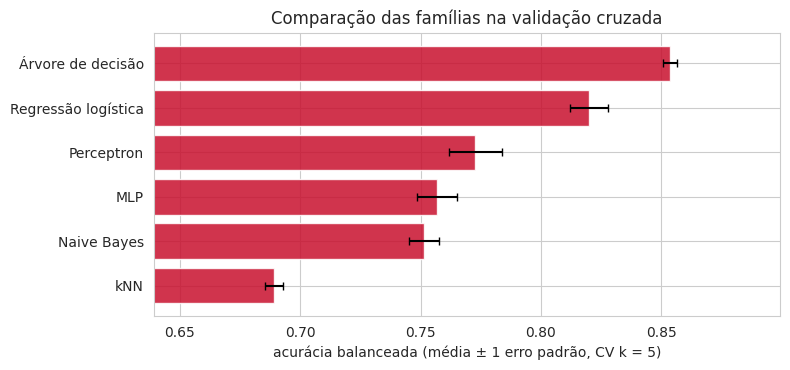

In [ ]:
linhas = []
for nome, r in resultados.items():
    gs = r['gs']
    i = gs.best_index_
    cvr = gs.cv_results_
    n_folds = cv.get_n_splits()
    media = cvr['mean_test_bal_acc'][i]
    desvio = cvr['std_test_bal_acc'][i] * np.sqrt(n_folds / (n_folds - 1))   # desvio amostral (ddof=1), como nas curvas
    linhas.append({
        'Família': nome,
        'Melhores hiperparâmetros': fmt_params(gs.best_params_),
        'Acc. balanceada (média)': media,
        'Desvio': desvio,
        'Erro padrão': desvio / np.sqrt(n_folds),
        'F1 classe positiva (média)': cvr['mean_test_f1'][i],
        'Tempo da busca (s)': r['tempo_busca'],
        'Tempo de ajuste por fold (s)': cvr['mean_fit_time'][i],
    })

tabela_cv = (pd.DataFrame(linhas)
             .sort_values('Acc. balanceada (média)', ascending=False)
             .reset_index(drop=True))
tabela_cv.index = tabela_cv.index + 1
display(tabela_cv.round({'Acc. balanceada (média)': 4, 'Desvio': 4, 'Erro padrão': 4,
                         'F1 classe positiva (média)': 4, 'Tempo da busca (s)': 1,
                         'Tempo de ajuste por fold (s)': 2}))

fig, ax = plt.subplots(figsize=(8, 3.8))
t = tabela_cv.iloc[::-1]
ax.barh(t['Família'], t['Acc. balanceada (média)'], xerr=t['Erro padrão'], color='#C8102E', alpha=0.85, capsize=3)
ax.set_xlim(max(0.5, t['Acc. balanceada (média)'].min() - 0.05), None)
ax.set_xlabel('acurácia balanceada (média ± 1 erro padrão, CV k = 5)')
ax.set_title('Comparação das famílias na validação cruzada')
plt.tight_layout(); plt.show()

### Leitura da tabela de CV

A **árvore de decisão** lidera com acurácia balanceada de 0,854 (erro padrão 0,003), seguida pela **regressão logística** (0,820; EP 0,008). A diferença de 0,034 equivale a cerca de 4 erros padrão combinados, então a vantagem da árvore não é ruído de amostragem. Em um grupo intermediário vêm o Perceptron (0,773), a MLP (0,757) e o Naive Bayes (0,751): a MLP e o Naive Bayes são indistinguíveis dentro do erro padrão, e o Perceptron fica um pouco acima, a 1 ou 2 erros padrão. O **kNN** é o último (0,689).

O F1 da classe positiva mostra um detalhe: a MLP tem F1 (0,629) praticamente igual ao da árvore (0,630) e ao da regressão logística (0,624), mas acurácia balanceada bem menor. Isso sugere que ela acerta bem as compras que prevê (boa precisão) e deixa passar muitas (recall baixo), o que a acurácia balanceada penaliza. É uma hipótese plausível, já que MLP, kNN e Naive Bayes não têm `class_weight`; ela será conferida pelo recall no teste (Seção 8).

Sobre a forma da fronteira: o melhor modelo é uma árvore rasa (profundidade 4) e a regressão logística, linear, é a segunda colocada, à frente de Perceptron, MLP e kNN. Isso é coerente com a exploração da E1, em que poucos atributos (`PageValues` à frente, depois `ExitRates` e `BounceRates`) concentram a maior parte do sinal, e com uma estrutura que não pede modelos muito flexíveis.

Custo: a árvore entrega o melhor desempenho com ajuste barato (0,10 s por fold) e a regressão logística é a alternativa de custo parecido (0,15 s). A MLP é a mais cara por ajuste (2,8 s) e não traz ganho. O tempo total da busca também depende do tamanho da grade (árvore 90 combinações, kNN 22, MLP 21); no kNN o custo está na predição sobre os folds, e não no ajuste.

## Seção 6 — Estudo de overfitting, viés e variância

**Lacuna treino–validação por família.** Para o melhor ponto de cada família, comparamos a acurácia balanceada média no treino dos folds com a da validação dos folds. Lacuna grande indica variância alta (modelo decora o treino); lacuna pequena com desempenho baixo em ambos indica viés alto (modelo simples demais).

,Família,Treino (média),Validação (média),Lacuna (treino − validação)
0,kNN,1.0000,0.6891,0.3109
1,MLP,0.7875,0.7570,0.0305
2,Árvore de decisão,0.8620,0.8537,0.0083
3,Regressão logística,0.8256,0.8201,0.0055
4,Perceptron,0.7773,0.7726,0.0047
5,Naive Bayes,0.7543,0.7514,0.0029


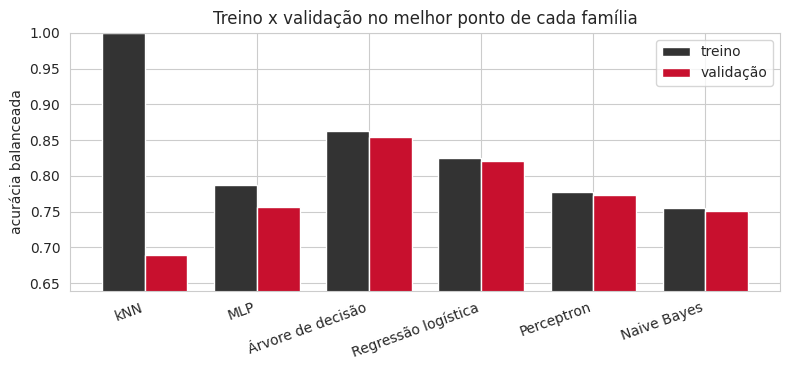

In [ ]:
linhas = []
for nome, r in resultados.items():
    gs = r['gs']; i = gs.best_index_; cvr = gs.cv_results_
    tr, va = cvr['mean_train_bal_acc'][i], cvr['mean_test_bal_acc'][i]
    linhas.append({'Família': nome, 'Treino (média)': tr, 'Validação (média)': va, 'Lacuna (treino − validação)': tr - va})
lacuna = pd.DataFrame(linhas).sort_values('Lacuna (treino − validação)', ascending=False).reset_index(drop=True)
display(lacuna.round(4))

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(lacuna)); w = 0.38
ax.bar(x - w/2, lacuna['Treino (média)'], w, label='treino', color='#333333')
ax.bar(x + w/2, lacuna['Validação (média)'], w, label='validação', color='#C8102E')
ax.set_xticks(x); ax.set_xticklabels(lacuna['Família'], rotation=20, ha='right')
ax.set_ylim(max(0.5, lacuna[['Treino (média)', 'Validação (média)']].min().min() - 0.05), 1.0)
ax.set_ylabel('acurácia balanceada'); ax.legend(); ax.set_title('Treino x validação no melhor ponto de cada família')
plt.tight_layout(); plt.show()

### Curvas de validação (árvore, kNN e MLP) com faixa de ±1 erro padrão

Para cada curva, variamos **um** hiperparâmetro e mantemos os demais nos valores do campeão da busca. A faixa sombreada é ±1 erro padrão entre os 5 folds. Duas regras de escolha:

- **Melhor média:** o valor com maior média de validação.
- **1 erro padrão:** o modelo *mais simples* cuja média está a até 1 erro padrão da melhor média (árvore: menor profundidade; kNN: maior k; MLP: maior `alpha`).

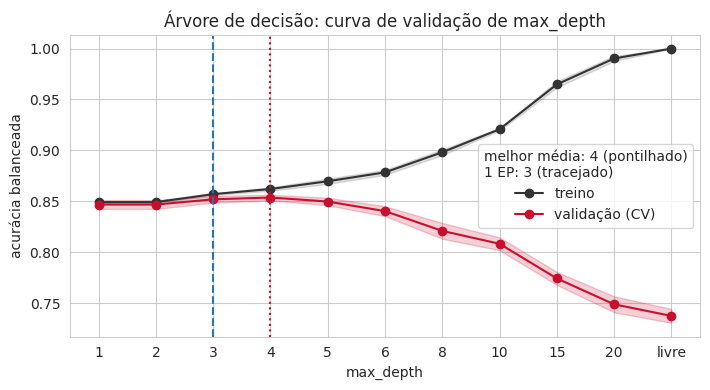

Árvore de decisão: melhor média em 4 (validação 0.8537 ± 0.0028); regra de 1 EP escolhe 3 (validação 0.8519 ± 0.0033).


In [ ]:
def regra_1ep(medias, ses, simples_no_inicio):
    ib = int(np.argmax(medias))
    limiar = medias[ib] - ses[ib]
    candidatos = [i for i, m in enumerate(medias) if m >= limiar]
    return ib, (min(candidatos) if simples_no_inicio else max(candidatos))

def curva_validacao(nome, param, valores, rotulos, simples_no_inicio, titulo, xlabel, log=False):
    base = clone(resultados[nome]['gs'].best_estimator_)
    tr, va = validation_curve(base, X_dev, y_dev, param_name=param, param_range=valores,
                              cv=cv, scoring='balanced_accuracy', n_jobs=-1)
    n = tr.shape[1]
    m_tr, m_va = tr.mean(axis=1), va.mean(axis=1)
    se_tr, se_va = tr.std(axis=1, ddof=1) / np.sqrt(n), va.std(axis=1, ddof=1) / np.sqrt(n)
    ib, i1 = regra_1ep(m_va, se_va, simples_no_inicio)

    xs = np.arange(len(valores))
    plt.figure(figsize=(7.2, 4))
    plt.plot(xs, m_tr, 'o-', color='#333333', label='treino')
    plt.fill_between(xs, m_tr - se_tr, m_tr + se_tr, color='#333333', alpha=0.15)
    plt.plot(xs, m_va, 'o-', color='#C8102E', label='validação (CV)')
    plt.fill_between(xs, m_va - se_va, m_va + se_va, color='#C8102E', alpha=0.20)
    plt.axvline(ib, ls=':', color='#C8102E'); plt.axvline(i1, ls='--', color='#1f77b4')
    plt.xticks(xs, rotulos, rotation=0)
    plt.xlabel(xlabel); plt.ylabel('acurácia balanceada'); plt.title(titulo)
    plt.legend(title=f"melhor média: {rotulos[ib]} (pontilhado)\n1 EP: {rotulos[i1]} (tracejado)", loc='best')
    plt.tight_layout(); plt.show()
    print(f"{nome}: melhor média em {rotulos[ib]} (validação {m_va[ib]:.4f} ± {se_va[ib]:.4f}); "
          f"regra de 1 EP escolhe {rotulos[i1]} (validação {m_va[i1]:.4f} ± {se_va[i1]:.4f}).")
    return pd.DataFrame({xlabel: rotulos, 'treino': m_tr, 'EP treino': se_tr, 'validação': m_va, 'EP validação': se_va})

# Árvore: max_depth (do mais simples para o mais complexo)
prof = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, None]
c_arv = curva_validacao('Árvore de decisão', 'clf__max_depth', prof, [str(p) if p else 'livre' for p in prof],
                        True, 'Árvore de decisão: curva de validação de max_depth', 'max_depth')

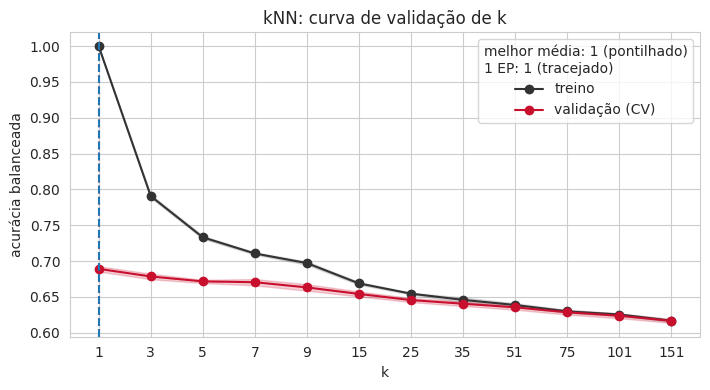

kNN: melhor média em 1 (validação 0.6891 ± 0.0037); regra de 1 EP escolhe 1 (validação 0.6891 ± 0.0037).


In [ ]:
# kNN: k (do maior k, mais simples, para o menor, mais complexo — o eixo cresce em k)
ks_curva = [1, 3, 5, 7, 9, 15, 25, 35, 51, 75, 101, 151]
c_knn = curva_validacao('kNN', 'clf__n_neighbors', ks_curva, [str(k) for k in ks_curva],
                        False, 'kNN: curva de validação de k', 'k')

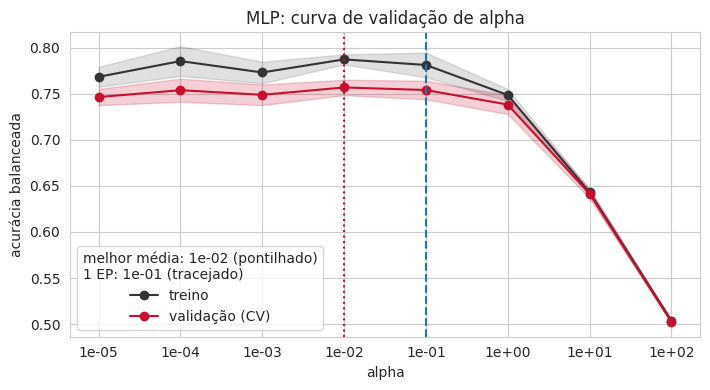

MLP: melhor média em 1e-02 (validação 0.7570 ± 0.0083); regra de 1 EP escolhe 1e-01 (validação 0.7542 ± 0.0101).


In [ ]:
# MLP: alpha (regularização L2; maior alpha = mais simples)
alphas = list(np.logspace(-5, 2, 8))
c_mlp = curva_validacao('MLP', 'clf__alpha', alphas, [f"{a:.0e}" for a in alphas],
                        False, 'MLP: curva de validação de alpha', 'alpha')

### Leitura em termos de viés e variância

**Lacuna treino–validação.** O kNN tem de longe a maior lacuna (treino 1,000 contra validação 0,689, diferença de 0,311): com k = 1 o modelo memoriza o treino, o caso mais claro de **variância alta**. A MLP vem depois (lacuna 0,031) e árvore, regressão logística, Perceptron e Naive Bayes ficam todos abaixo de 0,01, ou seja, com pouca variância. Mas lacuna pequena não significa bom modelo: Naive Bayes e Perceptron têm treino e validação praticamente iguais, em torno de 0,75 a 0,77, o que indica **viés alto** (modelos simples demais para esta fronteira). A árvore de profundidade 4 e a regressão logística combinam lacuna pequena com os melhores níveis de validação (0,854 e 0,820), o melhor equilíbrio entre viés e variância.

**Árvore (`max_depth`).** De 1 a 3, treino e validação andam juntos (cerca de 0,85) e a curva é plana: o modelo é simples, com viés dominante, mas quase tão bom quanto o melhor. A validação atinge o pico em `max_depth = 4` (0,854 ± 0,003) e, a partir de 5, o treino continua subindo (chega a 1,000 sem limite) enquanto a validação despenca (cerca de 0,74 sem limite): é o retrato clássico de **overfitting**, com a variância crescendo à medida que a árvore decora o treino. A regra de 1 erro padrão escolheria `max_depth = 3` (0,852 ± 0,003); a diferença para a profundidade 4 (0,002) é menor que 1 EP, então as duas são equivalentes estatisticamente, e a de 1 EP é a mais simples.

**kNN (k).** A validação *cai* de forma monótona com k (0,689 em k = 1 até cerca de 0,617 em k = 151), enquanto o treino despenca de 1,000 para cerca de 0,617, até as duas curvas praticamente se encontrarem. Em k pequeno há alta variância (grande lacuna); em k grande o **viés** domina: sem `class_weight`, os votos dos vizinhos tendem a ser dominados pela classe majoritária (85% das sessões), o que provavelmente reduz o recall da classe "compra" e puxa a acurácia balanceada em direção ao patamar trivial (0,5). Essa explicação será conferida no recall por classe (Seção 8). Por isso o melhor k é o menor possível (k = 1), tanto na melhor média quanto na regra de 1 EP: aqui a acurácia balanceada premia quem preserva o recall da minoria, e não quem suaviza a fronteira. Isso é o oposto do que ocorreu na E1, em que a acurácia simples crescia com k (melhor k = 9) enquanto o F1 caía: a métrica escolhida muda o campeão.

**MLP (`alpha`).** Entre 1e-5 e 1e-1 a curva é quase plana (treino cerca de 0,77 a 0,79, validação cerca de 0,746 a 0,757, lacuna de cerca de 0,03 com faixas largas): a regularização quase não altera o resultado nessa faixa. Para `alpha` ≥ 1 treino e validação caem juntos (0,74 em 1, 0,64 em 10 e 0,50 em 100, o patamar de um classificador trivial): é **viés alto** por excesso de regularização (os pesos são encolhidos até o modelo não aprender). A melhor média está em `alpha = 0,01` (0,757 ± 0,008) e a regra de 1 EP escolheria `alpha = 0,1` (0,754 ± 0,010); as faixas se sobrepõem totalmente, então as duas são equivalentes.

**Síntese.** Nas três famílias a regra de 1 EP aponta para o mesmo ponto (kNN) ou para um vizinho estatisticamente equivalente (árvore e MLP), e mantivemos a regra de melhor média para declarar os campeões. Em nenhuma família o problema principal é falta de flexibilidade: onde há variância (kNN com k pequeno, árvore profunda) ela vem de excesso de flexibilidade, e onde há viés (Naive Bayes, Perceptron, regularização forte) o desempenho fica abaixo do da árvore rasa.

## Seção 7 — Avaliação final no teste

### Declaração dos campeões (feita antes do teste)

Os campeões abaixo vêm exclusivamente da validação cruzada no desenvolvimento (Seções 4 a 6). Cada campeão é o `best_estimator_` do `GridSearchCV`, que já foi **reajustado no desenvolvimento inteiro** (treino + validação, 9.864 sessões) com os melhores hiperparâmetros. O custo é pequeno, então o reajuste foi viável para todas as famílias.

In [ ]:
campeoes = {nome: r['gs'].best_estimator_ for nome, r in resultados.items()}
campeao_geral = tabela_cv.iloc[0]['Família']

decl = tabela_cv[['Família', 'Melhores hiperparâmetros', 'Acc. balanceada (média)', 'Erro padrão']].copy()
display(decl.round({'Acc. balanceada (média)': 4, 'Erro padrão': 4}))
print(f"Campeão geral (maior acurácia balanceada média na validação cruzada): {campeao_geral}")

,Família,Melhores hiperparâmetros,Acc. balanceada (média),Erro padrão
1,Árvore de decisão,"{'class_weight': 'balanced', 'max_depth': 4, '...",0.8537,0.0028
2,Regressão logística,"{'C': 0.316, 'class_weight': 'balanced'}",0.8201,0.0078
3,Perceptron,"{'alpha': 1e-05, 'class_weight': 'balanced'}",0.7726,0.0110
4,MLP,"{'alpha': 0.01, 'hidden_layer_sizes': (64,)}",0.7570,0.0083
5,Naive Bayes,{'var_smoothing': 0.1},0.7514,0.0062
6,kNN,"{'n_neighbors': 1, 'weights': 'uniform'}",0.6891,0.0037


Campeão geral (maior acurácia balanceada média na validação cruzada): Árvore de decisão


**Declaração dos campeões:** com base exclusivamente na validação cruzada no desenvolvimento (acurácia balanceada, k = 5, regra de melhor média), declaramos, antes de usar o teste: **árvore de decisão** com `max_depth = 4`, `min_samples_leaf = 1` e `class_weight = 'balanced'`; **kNN** com `k = 1` e pesos uniformes; **Naive Bayes** com `var_smoothing = 0,1` (grade estendida até 1e2, ótimo no interior); **regressão logística** com `C = 0,316` e `class_weight = 'balanced'`; **Perceptron** com `alpha = 1e-5` e `class_weight = 'balanced'`; e **MLP** com uma camada oculta de 64 neurônios e `alpha = 0,01`. O **campeão geral** é a **árvore de decisão** (maior acurácia balanceada média na validação cruzada, 0,854). A regra de 1 erro padrão (árvore em profundidade 3, MLP com `alpha = 0,1`) foi analisada na Seção 6 apenas como sensibilidade. Nenhuma decisão desta entrega usou o teste (o uso do teste na E1 está registrado nas limitações).

In [ ]:
from sklearn.metrics import (balanced_accuracy_score, accuracy_score, f1_score,
                             precision_score, recall_score, confusion_matrix, classification_report)

TESTE_LIBERADO = True      # >>> mudar para True quando preencher sobre campeoes
LOG_PATH = 'test_log.csv'
RES_PATH = 'test_resultados.json'

def avaliar_teste_uma_vez(modelos, X_t, y_t):
    # Teste já avaliado antes: apenas recarrega o resultado registrado, SEM reavaliar o teste.
    assinatura = {n: str(fmt_params(resultados[n]['gs'].best_params_)) for n in modelos}
    if os.path.exists(RES_PATH):
        print("Teste já avaliado anteriormente: carregando o resultado registrado (o teste NÃO foi reavaliado).")
        with open(RES_PATH) as f:
            salvo = json.load(f)
        if salvo.get('_assinatura') != assinatura:
            print("ATENÇÃO: os hiperparâmetros dos campeões mudaram depois da avaliação do teste. "
                  "NÃO reavalie o teste: informe o professor e declare o fato nesta seção.")
        return salvo
    if not TESTE_LIBERADO:
        print("Teste BLOQUEADO (TESTE_LIBERADO = False). Declare os campeões e libere a flag para avaliar.")
        return None

    res = {}
    for nome, m in modelos.items():
        pred = m.predict(X_t)
        res[nome] = {
            'y_pred': [int(p) for p in pred],
            'bal_acc': float(balanced_accuracy_score(y_t, pred)),
            'acc': float(accuracy_score(y_t, pred)),
            'f1': float(f1_score(y_t, pred)),
            'precisao_pos': float(precision_score(y_t, pred, zero_division=0)),
            'recall_pos': float(recall_score(y_t, pred, pos_label=1)),
            'recall_neg': float(recall_score(y_t, pred, pos_label=0)),
        }
    res['_assinatura'] = assinatura
    with open(RES_PATH, 'w') as f:
        json.dump(res, f)
    novo = not os.path.exists(LOG_PATH)
    with open(LOG_PATH, 'a') as f:
        if novo:
            f.write('data_hora,evento,detalhe\n')
        f.write(f"{datetime.now().isoformat(timespec='seconds')},avaliacao_unica_do_teste,{len(modelos)} campeoes\n")
    print("Teste avaliado UMA ÚNICA VEZ e registrado.")
    return res

res_teste = avaliar_teste_uma_vez(campeoes, X_teste, y_teste)

print("\nRegistro de uso do teste (test_log.csv):")
print(open(LOG_PATH).read() if os.path.exists(LOG_PATH) else "(nenhum uso do teste registrado ainda)")

Teste avaliado UMA ÚNICA VEZ e registrado.

Registro de uso do teste (test_log.csv):
data_hora,evento,detalhe
2026-10-28T00:34:41,avaliacao_unica_do_teste,6 campeoes



### Tabela: validação cruzada x teste

In [ ]:
if res_teste is None:
    print("Teste ainda bloqueado: esta tabela aparece depois que o teste for liberado e avaliado.")
else:
    linhas = []
    for _, lin in tabela_cv.iterrows():
        nome = lin['Família']; t = res_teste[nome]
        linhas.append({
            'Família': nome,
            'CV: acc. balanceada': lin['Acc. balanceada (média)'],
            'CV: erro padrão': lin['Erro padrão'],
            'Teste: acc. balanceada': t['bal_acc'],
            'Teste − CV': t['bal_acc'] - lin['Acc. balanceada (média)'],
            'Teste: F1 (compra)': t['f1'],
            'Teste: recall (compra)': t['recall_pos'],
            'Teste: precisão (compra)': t['precisao_pos'],
            'Teste: acurácia': t['acc'],
        })
    tabela_final = pd.DataFrame(linhas)
    tabela_final.index = tabela_final.index + 1
    display(tabela_final.round(4))

,Família,CV: acc. balanceada,CV: erro padrão,Teste: acc. balanceada,Teste − CV,Teste: F1 (compra),Teste: recall (compra),Teste: precisão (compra),Teste: acurácia
1,Árvore de decisão,0.8537,0.0028,0.8392,-0.0145,0.6229,0.8325,0.4977,0.8439
2,Regressão logística,0.8201,0.0078,0.8026,-0.0175,0.5954,0.7435,0.4965,0.8435
3,Perceptron,0.7726,0.0110,0.7742,0.0016,0.5071,0.7932,0.3727,0.7612
4,MLP,0.7570,0.0083,0.7219,-0.0351,0.5705,0.4817,0.6996,0.8877
5,Naive Bayes,0.7514,0.0062,0.7277,-0.0237,0.4864,0.6335,0.3948,0.7928
6,kNN,0.6891,0.0037,0.6565,-0.0326,0.4276,0.3979,0.4620,0.8350


### Discussão: validação cruzada x teste

**Ordem das famílias.** O teste confirma o pódio da validação cruzada: árvore de decisão (0,839), regressão logística (0,803) e Perceptron (0,774), na mesma ordem. A única troca ocorre entre a 4ª e a 5ª posições: o Naive Bayes (0,728) passou à frente da MLP (0,722). Essas duas já eram estatisticamente indistinguíveis na validação cruzada (0,751 ± 0,006 contra 0,757 ± 0,008), então a inversão é compatível com ruído amostral, e não com um erro de seleção. O kNN segue em último (0,657).

**Diferença entre teste e validação cruzada.** Cinco das seis famílias caíram um pouco no teste (de −0,015 a −0,035) e o Perceptron praticamente não mudou (+0,002). Para avaliar se isso é grande, estimamos o erro padrão da acurácia balanceada no teste a partir dos recalls por classe (382 compras e 2.084 não compras), que fica em torno de 0,010 a 0,013 por família. Combinando com o erro padrão da validação cruzada, as quedas equivalem a cerca de 1,2 a 1,6 erros padrão em árvore, regressão logística e Naive Bayes, e a cerca de 2,3 a 2,4 em MLP e kNN. Ou seja: a queda é pequena e consistente, não há colapso em nenhuma família, e a busca por validação cruzada não superestimou muito o desempenho.

**Por que a queda é quase sempre negativa.** Esse viés de sinal é esperado: ao escolher a melhor configuração de cada grade pela validação cruzada, aproveitamos um pouco do ruído dos folds, então a estimativa de desenvolvimento tende a ficar levemente otimista. É coerente que as duas maiores quedas estejam na MLP e no kNN, duas famílias cuja escolha ficou em um ponto sensível: a MLP tem faixas de ±1 erro padrão largas e quase planas entre `alpha` de 1e-5 a 1e-1 (Seção 6), e o kNN venceu em `k = 1`, o ponto de maior variância. Esses resultados são relatados como vieram, sem retornar à busca para ajustá-los (regra 4 do guia).

**Acurácia balanceada contra acurácia simples.** A árvore campeã tem acurácia simples de 0,844 no teste, praticamente igual ao patamar trivial de 84,5% de quem sempre prevê "não compra" — e, ainda assim, acurácia balanceada de 0,839 contra 0,5 desse classificador trivial. O contraste mostra por que a métrica principal foi escolhida antes da busca: pela acurácia simples, o campeão pareceria não ter aprendido nada. A MLP ilustra o outro lado: é a família com **maior** acurácia simples no teste (0,888), mas só a 5ª em acurácia balanceada, porque acerta quase tudo na classe majoritária (recall de 0,962 em "não compra") e menos da metade das compras (recall de 0,482). A hipótese levantada na Seção 5 — MLP com boa precisão e recall baixo na classe positiva, por não ter `class_weight` — fica confirmada: a precisão dela na classe "compra" é a maior de todas (0,700), com o menor recall entre as famílias razoáveis.

## Seção 8 — Erros por classe

Matriz de confusão e recall por classe do **campeão geral**, declarado antes do teste.

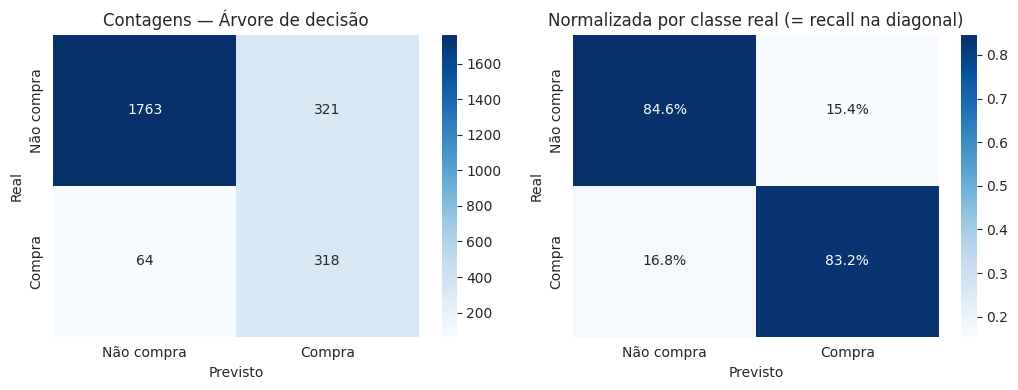

              precision    recall  f1-score   support

  Não compra      0.965     0.846     0.902      2084
      Compra      0.498     0.832     0.623       382

    accuracy                          0.844      2466
   macro avg      0.731     0.839     0.762      2466
weighted avg      0.893     0.844     0.858      2466



In [ ]:
if res_teste is None:
    print("Teste ainda bloqueado: a matriz de confusão aparece depois que o teste for avaliado.")
else:
    pred = np.array(res_teste[campeao_geral]['y_pred'])
    cm = confusion_matrix(y_teste, pred)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)

    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
    rot = ['Não compra', 'Compra']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], xticklabels=rot, yticklabels=rot)
    axes[0].set_title(f'Contagens — {campeao_geral}')
    sns.heatmap(cm_norm, annot=True, fmt='.1%', cmap='Blues', ax=axes[1], xticklabels=rot, yticklabels=rot)
    axes[1].set_title('Normalizada por classe real (= recall na diagonal)')
    for ax in axes:
        ax.set_xlabel('Previsto'); ax.set_ylabel('Real')
    plt.tight_layout(); plt.show()

    print(classification_report(y_teste, pred, target_names=rot, digits=3))

### Interpretação

O campeão (árvore de decisão com `max_depth = 4` e `class_weight = 'balanced'`) **encontra 83,2% das sessões que realmente terminaram em compra** (318 de 382; recall da classe "Compra"), e deixa passar 64 compradores. Na classe majoritária, acerta 84,6% (1.763 de 2.084), com 321 falsos alarmes. Os dois recalls são quase iguais, o que era o objetivo de otimizar acurácia balanceada: o modelo não troca a minoria pela maioria.

A **precisão da classe "Compra" é de 49,8%**: entre as 639 sessões que o modelo aponta como compra, cerca de metade de fato comprou. Esse é o custo do ponto de operação escolhido. Com 15,5% de compras na base, um palpite aleatório acertaria 15,5%, então 49,8% é mais de três vezes o acaso — mas está longe de ser uma previsão confiável caso a caso.

**Qual erro é mais caro.** Depende do uso. Se o objetivo for acionar uma campanha de retenção (cupom, lembrete de carrinho), o falso alarme custa pouco — um desconto para quem talvez comprasse de qualquer forma — enquanto perder um comprador em potencial custa a venda inteira. Nesse caso o ponto atual é adequado, e até valeria aumentar ainda mais o recall. Se o objetivo for algo caro por contato (ligação de um vendedor, por exemplo), 321 falsos alarmes para 318 acertos é caro demais, e seria melhor subir o limiar de decisão em troca de precisão, aceitando perder recall.

**Erro dominante.** Em número absoluto, o modelo erra muito mais na classe majoritária (321 falsos positivos contra 64 falsos negativos), simplesmente porque ela é 5,5 vezes maior. Em proporção, os dois erros são equivalentes (15,4% e 16,8%). Vale notar que esse equilíbrio não é automático: ele vem do `class_weight = 'balanced'`, escolhido pela busca. Sem ele, como se vê na MLP e no kNN, o modelo tenderia a favorecer a classe majoritária e o recall das compras cairia bastante.

## Seção 9 — Conclusões

**Resposta à pergunta do projeto.** Sim, o comportamento de navegação permite prever com utilidade prática se uma sessão termina em compra, mas não com confiabilidade caso a caso. O melhor modelo entre as seis famílias — uma árvore de decisão rasa (`max_depth = 4`, `min_samples_leaf = 1`, `class_weight = 'balanced'`) — alcança **acurácia balanceada de 0,839 no teste**, contra 0,5 de um classificador trivial que sempre responde "não compra", e identifica **83,2% das compras reais** com recall equivalente na outra classe. Em contrapartida, apenas metade das sessões que ele aponta como compra de fato comprou (precisão de 49,8%), o que torna o modelo adequado para priorizar ações de baixo custo por contato, e não para decisões caras sobre sessões individuais.

Dois achados sustentam essa leitura. Primeiro, a fronteira do problema é simples: uma árvore de profundidade 4 supera MLP, kNN e Naive Bayes, e a regressão logística (linear) fica em segundo lugar — coerente com a exploração da Entrega 1, em que poucos atributos (`PageValues` à frente, depois `ExitRates` e `BounceRates`) concentram a maior parte do sinal. Segundo, a escolha da métrica muda a conclusão: pela acurácia simples a MLP pareceria a melhor família (0,888) e o campeão pareceria não ter aprendido nada (0,844, igual ao patamar trivial); é a acurácia balanceada que separa quem encontra compradores de quem apenas acompanha a classe majoritária.

**Limitações.**

1. **Uso do teste na Entrega 1.** O conjunto de teste foi consultado na E1 (decomposição viés-variância e acurácia dos campeões), embora os hiperparâmetros daquela entrega tenham sido escolhidos pela validação. O teste da E2 é, portanto, o mesmo da E1 e não é totalmente virgem; a estimativa de desempenho final pode estar levemente otimista.
2. **Uma única divisão treino/teste.** O resultado no teste é uma única amostra; sua incerteza não é medida. A validação cruzada ajuda no desenvolvimento, mas o número final vem de 2.466 sessões (cerca de 382 compras).
3. **Comparação não totalmente simétrica.** `class_weight` existe para árvore, regressão logística e Perceptron, mas não para kNN, Naive Bayes e MLP. As grades têm tamanhos diferentes, o que dá mais chances de ajuste fino a algumas famílias.
4. **Naive Bayes gaussiano com atributos one-hot.** A suposição de normalidade é violada; o resultado serve como baseline e não como o melhor que a família poderia fazer.
5. **Duplicatas mantidas.** As 125 linhas duplicadas foram mantidas (decisão da E1); duplicatas em folds diferentes podem inflar levemente a validação cruzada.
6. **Sem devolutiva da E1** até a data da entrega; as correções incorporadas foram as que nós mesmos identificamos (Seção 1).
7. **Ótimos na borda da grade.** Em kNN (`k = 1`) e árvore (`min_samples_leaf = 1`) o ótimo está no limite natural do hiperparâmetro e não pôde ser estendido; no Naive Bayes a grade foi estendida até 1e2 e o ótimo passou a ficar no interior (Seção 4). Além disso, o kNN ter vencido com `k = 1` decorre da combinação entre a métrica (acurácia balanceada) e a ausência de `class_weight` no kNN (Seção 6), e não de boa generalização: com acurácia simples, como na E1, o melhor k foi 9.

**Próximos passos.** (1) modelos de conjunto (Random Forest, Gradient Boosting) e ajuste do limiar de decisão para a classe "Compra"; (2) tratar o desbalanceamento de forma uniforme em todas as famílias (reamostragem dentro do fold, por exemplo); (3) seleção de atributos ou redução de dimensionalidade para as famílias baseadas em distância; (4) validação cruzada repetida para quantificar melhor a incerteza; (5) usar métricas atreladas ao custo de negócio.

## Seção 10 — Opcionais
Optamos por não incluir nem o LVQ nem a extensão bônus nesta entrega.

O **LVQ** já havia sido implementado e analisado como bônus na Entrega 1, com busca do número de protótipos pela validação e comparação de viés e variância com kNN e árvore. Repeti-lo aqui, sem pontos extras, acrescentaria um sétimo modelo baseado em distância a uma comparação em que as duas famílias desse tipo (kNN e MLP) já ficaram entre as últimas colocadas — e o diagnóstico da Seção 6 explica por quê: em um espaço com cerca de 70 dimensões após o one-hot, e sem `class_weight`, os métodos baseados em distância tendem à classe majoritária e perdem recall na classe "compra".

A **extensão bônus** (um modelo além do curso, como LightGBM) não foi incluída por uma razão de protocolo: o guia exige que a grade e o critério do opcional sejam declarados na Seção 7 **antes** da avaliação do teste, e nossa declaração de campeões já estava fechada quando consideramos a possibilidade. Acrescentar um sétimo modelo depois de conhecer o desempenho dos seis no teste significaria montar sua grade com informação que o protocolo reserva para o final, o que invalidaria a comparação — mesmo que o resultado numérico fosse favorável. Preferimos manter a integridade do protocolo a buscar o ponto adicional.

Fica registrado como próximo passo (Seção 9) avaliar modelos de conjunto, incluindo gradient boosting, em um protocolo em que sua grade seja declarada antes de qualquer contato com o teste.

## Seção 11 — Declaração de uso de IA

**Ferramentas:** Claude (Anthropic).

**Para quê:** usamos o Claude como apoio na estruturação do notebook segundo as seções do guia, na escrita e revisão do código do protocolo (Pipeline, validação cruzada, buscas por grade, curvas de validação com faixa de erro padrão, mecanismo de registro e bloqueio do teste) e na redação dos textos de interpretação a partir dos resultados que obtivemos.

**O que fizemos:** conduzimos a execução e a validação de ponta a ponta. Rodamos o notebook em várias passadas, conferimos a divisão recuperada contra os números da Entrega 1 (7398/2466/2466 e as proporções de classe), analisamos a verificação de borda das grades e decidimos estender a do Naive Bayes até 1e2, refazendo a busca para confirmar que o ótimo passava a ficar no interior. Comparamos as seis famílias pela tabela de validação cruzada, lemos as três curvas de validação em termos de viés e variância, e confrontamos as hipóteses levantadas no desenvolvimento com o que o teste mostrou — foi assim que confirmamos, pelo recall por classe, que o desempenho fraco da MLP em acurácia balanceada vinha de recall baixo na classe "compra", e não de erro de ajuste. Mantivemos o teste bloqueado até a declaração dos campeões estar escrita, liberamos a flag uma única vez e decidimos não incluir a extensão bônus justamente para não declarar uma grade depois de conhecer o resultado do teste (Seção 10).

**Como verificamos:** cada trecho de código sugerido foi executado e conferido contra as saídas reais antes de ser incorporado; os textos de interpretação foram escritos sobre os números que apareceram na nossa execução e revisados por nós. As decisões de protocolo — pré-processamento dentro do Pipeline, escolha da acurácia balanceada antes da busca, declaração dos campeões antes do teste e uso único do teste — são compreendidas ao ponto de poderem ser explicadas e justificadas por nós na arguição.

In [ ]:
print(f"Tempo total da execução: {(time.time() - T0) / 60:.1f} minutos")

Tempo total da execução: 7.5 minutos
